# 06 — La función de decisión

**La pregunta rectora:**

> Dado un presupuesto de USD 80.000 a 200.000 y un horizonte de 5 años, ¿qué propiedad
> ofrece la mejor combinación de retorno esperado, liquidez y riesgo, y supera esa
> combinación la de no comprar y quedarse en renta fija en dólares?

Se descompone en tres decisiones, cada una con un criterio declarado en la 2da entrega
antes de mirar los resultados:

| Decisión | Criterio |
|---|---|
| **P1** — ¿comprar o no comprar? | Recomendar la propiedad solo si su rentabilidad neta, calculada sobre el **extremo inferior** de su banda, supera el **techo** de la banda de retorno mínimo (7,60%) más un margen por liquidez |
| **P2** — ¿qué propiedad? | Recomendar A sobre B solo si sus bandas **no se superponen** |
| **P3** — ¿tradicional o temporal? | Neta contra neta: el temporal conviene solo si la ocupación que se puede sostener supera la **ocupación de equilibrio** de la celda |

**Implementar es la mitad. La otra mitad es evaluar:** cuántas propiedades pasan P1, en
qué proporción de los pares la banda permite distinguir, en cuántas celdas gana el
temporal, y cómo cambia todo eso si se mueven los supuestos.

El cálculo está en `src/decision.py`, que agrega las columnas de la decisión al dataset
analítico (son las que usa el tablero), y `src/test_decision.py` lo verifica contra la
comparación de todos los pares uno por uno y contra `kpis.py` y `temporal.py`.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import decision as D
import eda
import supuestos as S

eda.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

P = "../data/processed"
df = pd.read_csv(f"{P}/dataset_analitico.csv", encoding="utf-8-sig", low_memory=False)
for c in ["en_presupuesto", "en_soporte_modelo", "universo_decision", "p1_comprar", "p1_comprar_con_entrada",
          "p2_no_dominada"]:
    df[c] = df[c].fillna(False).astype(bool)
sens = pd.read_csv(f"{P}/decision_sensibilidad.csv", encoding="utf-8-sig")
p3 = pd.read_csv(f"{P}/decision_p3.csv", encoding="utf-8-sig")
temporal = pd.read_csv(f"{P}/temporal_vs_tradicional.csv", encoding="utf-8-sig")
techo = S.RETORNO_MIN_TECHO_PCT
print(f"Banda de retorno minimo: {S.RETORNO_MIN_PISO_PCT:.2f}% a {techo:.2f}%. Horizonte: {S.HORIZONTE_ANIOS} anios")

Banda de retorno minimo: 7.10% a 7.60%. Horizonte: 5 anios


## 1. El universo de la decisión y el soporte del modelo

Entran las ventas con estimación confiable y dentro del presupuesto. A eso se suma un
filtro que la 2da entrega no tenía: el **soporte del modelo**. Una propiedad entra solo
si su celda tipo × tramo de superficie tiene al menos 30 alquileres observados
(`supuestos.MIN_ALQ_SOPORTE`). La razón se ve abajo: sin el filtro, las primeras de la
lista son casas de 6 a 10 ambientes.

In [2]:
v = df[df["operacion"] == "venta"]
conf = v[v["estimacion_confiable"] == 1]
pres = conf[conf["en_presupuesto"]]
u = df[df["universo_decision"]].copy()
embudo = pd.DataFrame({"propiedades": [len(v), len(conf), len(pres), len(u)]},
                      index=["ventas", "con estimacion confiable", "dentro del presupuesto",
                             "en el soporte del modelo (universo)"])
display(embudo)
alq = df[df["operacion"] == "alquiler"]
display(pd.crosstab(alq["tipo_familia"], alq["superficie_rango"])[S.ORDEN_SUPERFICIE_RANGO]
        .rename_axis("alquileres observados"))

,propiedades
ventas,10749
con estimacion confiable,9203
dentro del presupuesto,5198
en el soporte del modelo (universo),4484


superficie_rango,hasta 35,36-55,56-80,81-120,120+
alquileres observados,,,,,
casa,0,0,1,1,12
departamento,314,587,232,109,48
ph,3,12,10,11,8


In [3]:
# Las cinco de mayor neta central dentro del presupuesto, SIN el filtro de soporte.
cols = ["barrio", "tipo_familia", "ambientes", "sup_total_m2", "venta_usd", "alquiler_est_usd_mes",
        "rent_neta_pct", "n_alq_celda_tipo"]
pres.sort_values("rent_neta_pct", ascending=False)[cols].head(5)

,barrio,tipo_familia,ambientes,sup_total_m2,venta_usd,alquiler_est_usd_mes,rent_neta_pct,n_alq_celda_tipo
2048,villa luro,casa,9.00,320.00,"190,000.00","5,232.33",27.40,12.00
9302,monserrat,ph,10.00,124.74,"105,000.00","2,421.06",23.04,8.00
5719,barracas,casa,8.00,230.30,"179,900.00","3,670.68",20.47,12.00
9556,flores,casa,6.00,233.00,"129,000.00","2,475.33",19.04,12.00
5522,parque chacabuco,casa,5.00,182.00,"112,000.00","2,113.72",18.79,12.00


**Lectura.** Hay 14 alquileres observados de casas y 44 de PH, contra 1.290 de
departamentos. Sin el filtro, la propiedad de mayor rentabilidad es una casa de 9
ambientes en Villa Luro (en realidad, "2 PH en block") a la que el modelo le estima
USD 5.000 de alquiler por mes. No es una oportunidad: es el modelo extrapolando donde
no tiene datos. **Las casas y los PH quedan fuera de las recomendaciones**: el trabajo no
tiene con qué compararlos entre sí ni contra un departamento. Siguen en el dataset, con
la columna `en_soporte_modelo` en falso.

## 2. P1 — ¿Comprar o no comprar?

**Método.** Para cada propiedad, la neta del **escenario pesimista**: el alquiler del
percentil 10 de su banda, con la misma vacancia y los mismos gastos que el KPI 2. El ABL
en pesos es el mismo, así que sobre un alquiler más bajo pesa más. Se recomienda comprar
si esa neta supera el techo de la banda de retorno mínimo. El margen por liquidez no
tiene fuente: en el caso base es 0, lo más favorable a comprar.

Como versión estricta se usa la **TIR pesimista a 5 años**, que suma los costos de
entrada y la refacción. Es la cifra que se compara de verdad con una ON a plazo
parecido.

In [4]:
p1 = pd.DataFrame({
    "pasan": [int(u["p1_comprar"].sum()), int(u["p1_comprar_con_entrada"].sum())],
    "% del universo": [u["p1_comprar"].mean() * 100, u["p1_comprar_con_entrada"].mean() * 100],
}, index=["neta pesimista > techo", "TIR pesimista a 5 anios > techo (con costos de entrada)"])
display(p1)
print(f"Neta del universo: pesimista mediana {u['neta_min_pct'].median():.2f}%, central mediana "
      f"{u['rent_neta_pct'].median():.2f}%, optimista mediana {u['neta_max_pct'].median():.2f}%")
print(f"Propiedades cuya neta CENTRAL supera el techo: {int((u['rent_neta_pct'] > techo).sum())}")

,pasan,% del universo
neta pesimista > techo,18,0.40
TIR pesimista a 5 anios > techo (con costos de entrada),4,0.09


Neta del universo: pesimista mediana 4.12%, central mediana 5.38%, optimista mediana 6.80%
Propiedades cuya neta CENTRAL supera el techo: 227


### Gráfico 13 — ¿Cuántas propiedades le ganan a una ON aun en el escenario pesimista?

Distribución de la rentabilidad neta pesimista (alquiler del percentil 10) de las
propiedades del universo, contra el techo de la banda de retorno mínimo.

guardado: ../graficos\13_p1_neta_pesimista.png


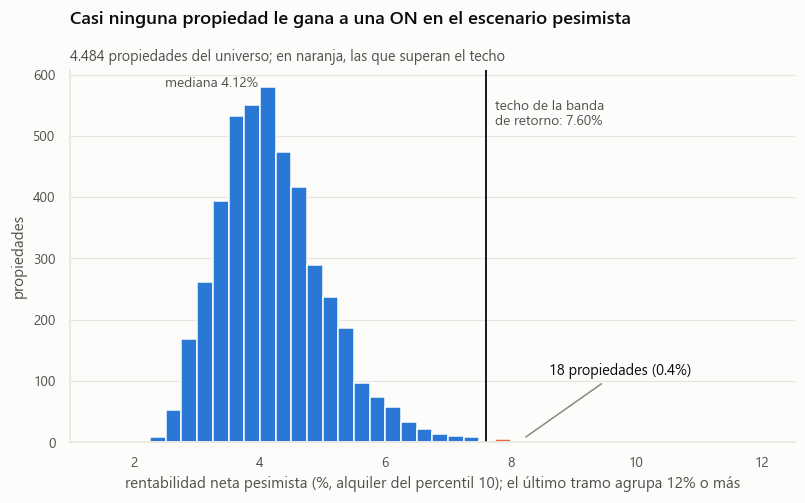

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = u["neta_min_pct"].clip(upper=12)
bordes = np.arange(1.5, 12.25, 0.25)
ax.hist(x[x <= techo], bins=bordes, color=eda.SERIE_1, edgecolor=eda.SUPERFICIE, linewidth=1)
ax.hist(x[x > techo], bins=bordes, color=eda.SERIE_2, edgecolor=eda.SUPERFICIE, linewidth=1)
ax.axvline(techo, color=eda.TINTA, linewidth=1.2)
ax.annotate(f"techo de la banda\nde retorno: {techo:.2f}%", (techo, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color=eda.TINTA_2, va="top")
n_p1 = int(u["p1_comprar"].sum())
ax.annotate(f"{n_p1} propiedades ({n_p1 / len(u):.1%})", (8.2, 6), xytext=(8.6, 110),
            fontsize=9.5, color=eda.TINTA, ha="left",
            arrowprops={"arrowstyle": "-", "color": eda.TINTA_3, "linewidth": 1})
ax.annotate(f"mediana {u['neta_min_pct'].median():.2f}%", (u["neta_min_pct"].median(), ax.get_ylim()[1] * 0.98),
            xytext=(-6, 0), textcoords="offset points", fontsize=9, color=eda.TINTA_2, ha="right", va="top")
ax.set_xlabel("rentabilidad neta pesimista (%, alquiler del percentil 10); el último tramo agrupa 12% o más")
ax.set_ylabel("propiedades")
ax.grid(False, axis="x")
eda.titulo(ax, "Casi ninguna propiedad le gana a una ON en el escenario pesimista",
           f"{len(u):,} propiedades del universo".replace(",", ".") + "; en naranja, las que superan el techo")
eda.guardar(fig, 13, "p1_neta_pesimista")
plt.show()

In [6]:
# Las que pasan: que tienen en comun.
cols = ["barrio", "superficie_rango", "ambientes", "venta_usd", "rent_neta_pct", "neta_min_pct", "neta_max_pct",
        "tir_5a_min_pct", "m2_relativo_celda", "a_reciclar", "p1_comprar_con_entrada", "titulo"]
pasan = u[u["p1_comprar"]].sort_values("neta_min_pct", ascending=False)
print(f"Precio del m2 contra el mediano de su celda barrio x tramo: mediana {pasan['m2_relativo_celda'].median():.2f} "
      f"(el universo: {u['m2_relativo_celda'].median():.2f})")
with pd.option_context("display.max_colwidth", 45):
    display(pasan[cols])

Precio del m2 contra el mediano de su celda barrio x tramo: mediana 0.69 (el universo: 1.02)


,barrio,superficie_rango,ambientes,venta_usd,rent_neta_pct,neta_min_pct,neta_max_pct,tir_5a_min_pct,m2_relativo_celda,a_reciclar,p1_comprar_con_entrada,titulo
3360,villa crespo,120+,5.00,"85,000.00",14.40,10.82,17.51,9.38,0.49,0,True,Venta 4 amb + dep V. Crespo. A refac. Fin...
10614,parque chacabuco,120+,7.00,"130,000.00",14.71,10.79,19.48,9.35,0.73,0,True,DEPTO 7 AMBIENTES EN VENTA PARQUE CHACABUCO
9446,san nicolas,120+,7.00,"110,000.00",15.39,9.99,19.56,8.58,0.69,0,True,Piso en venta 7 ambientes - Oportunidad
8377,balvanera,120+,7.00,"148,000.00",11.77,9.18,14.36,7.80,0.96,0,True,Venta departamento 6 ambientes tipo PH Fr...
6091,monserrat,120+,5.00,"95,000.00",12.54,8.84,19.95,5.12,0.43,1,False,departamento 5 ambientes a refaccionar / ...
6206,balvanera,81-120,5.00,"115,000.00",11.07,8.64,14.08,7.28,0.77,0,False,VENTA DPTO 5AMB BALVANERA APTO PROFESIONAL
6538,saavedra,81-120,5.00,"135,000.00",11.62,8.38,14.00,7.02,0.53,0,False,Venta Departamento 5 ambientes en Saavedr...
7955,constitucion,120+,4.00,"109,900.00",11.14,8.27,16.32,6.92,0.71,0,False,Departamento 4 Amb. al Frente en Constitu...
2145,san cristobal,81-120,4.00,"96,500.00",10.22,8.24,13.25,6.89,0.85,0,False,4 amb vista abierta en San Cristobal
10879,flores,81-120,4.00,"93,000.00",9.94,8.21,11.82,6.86,0.70,0,False,Venta Departamento 3 amb. c/posible 3°dor...


**Lectura.**

- **Para la propiedad típica, la respuesta a P1 es no comprar.** La neta pesimista
  mediana queda unos 3,5 puntos por debajo del techo. Incluso la neta central de la
  mayoría está debajo del piso: es el hallazgo central del trabajo, ahora como decisión.
- **Pasan muy pocas, y casi ninguna con costos de entrada.** Con la TIR a 5 años, que es
  la comparación honesta con una ON, el filtro deja un puñado de propiedades.
- **Las que pasan tienen algo en común: son baratas para su celda.** Cuestan alrededor de
  un 30% menos por m² que la mediana de su barrio y tramo. Puede ser una oportunidad o
  algo que el aviso no dice (estado, oficina, ubicación). **La función de decisión las
  señala para verificar, no para comprar a ciegas.** Es la columna `m2_relativo_celda`
  del tablero.

## 3. P2 — ¿Qué propiedad?

**Método.** A se recomienda sobre B solo si la neta pesimista de A supera la optimista
de B. Se mide en qué proporción de los pares eso ocurre, y cuáles propiedades **no están
dominadas** por ninguna otra (la frontera). Dentro de la frontera, ninguna se distingue
de otra por rentabilidad: la elección se decide por liquidez o por riesgo.

In [7]:
lo, hi = u["neta_min_pct"], u["neta_max_pct"]
pares = pd.DataFrame({"pares con bandas que no se superponen (%)": [
    D.pares_distinguibles(lo, hi) * 100,
    D.pares_distinguibles_por_grupo(lo, hi, u["superficie_rango"]) * 100,
    D.pares_distinguibles_por_grupo(lo, hi, u["barrio"]) * 100]},
    index=["todos los pares", "mismo tramo de superficie", "mismo barrio"])
display(pares)
front = u[u["p2_no_dominada"]]
print(f"Frontera: {len(front)} de {len(u):,} propiedades ({len(front) / len(u):.1%}). "
      f"Ancho mediano de la banda de neta: {(hi - lo).median():.2f} pp")
mejor = u["rent_neta_pct"].idxmax()
print(f"La de mayor neta central ({u.loc[mejor, 'rent_neta_pct']:.2f}%) supera con claridad al "
      f"{(hi < u.loc[mejor, 'neta_min_pct']).mean():.1%} del universo, pero no a las otras "
      f"{len(front) - 1} de la frontera")

,pares con bandas que no se superponen (%)
todos los pares,7.23
mismo tramo de superficie,5.19
mismo barrio,3.66


Frontera: 140 de 4,484 propiedades (3.1%). Ancho mediano de la banda de neta: 2.67 pp
La de mayor neta central (15.39%) supera con claridad al 94.4% del universo, pero no a las otras 139 de la frontera


### Gráfico 14 — ¿Las propiedades mejor rankeadas se distinguen entre sí?

Banda de rentabilidad neta (pesimista a optimista) de las 30 propiedades de mayor neta
central del universo, ordenadas por esa neta. La línea vertical es la mayor neta
pesimista del universo: toda banda que la alcanza está en la frontera.

guardado: ../graficos\14_p2_bandas_top30.png


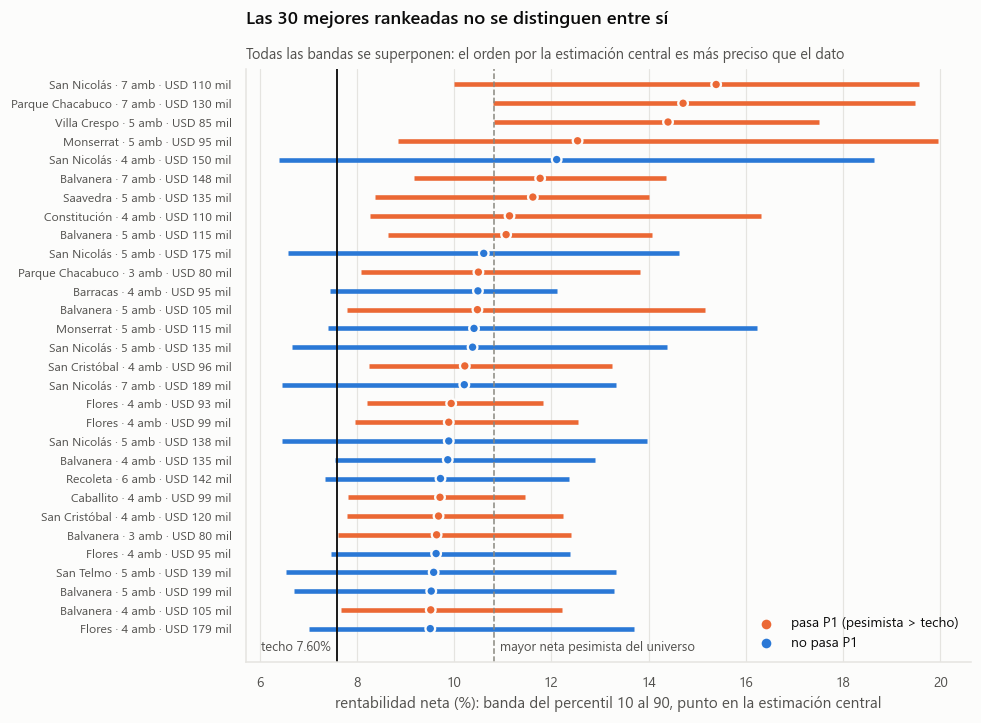

In [8]:
top = u.sort_values("rent_neta_pct", ascending=False).head(30)
corte = lo.max()
fig, ax = plt.subplots(figsize=(8.5, 7))
yy = np.arange(len(top))[::-1]
color = np.where(top["p1_comprar"], eda.SERIE_2, eda.SERIE_1)
ax.hlines(yy, top["neta_min_pct"], top["neta_max_pct"], color=color, linewidth=3)
ax.scatter(top["rent_neta_pct"], yy, s=40, color=color, edgecolor=eda.SUPERFICIE, linewidth=1.5, zorder=3)
ax.axvline(corte, color=eda.TINTA_3, linewidth=1, linestyle="--")
ax.axvline(techo, color=eda.TINTA, linewidth=1.2)
ax.annotate("mayor neta pesimista del universo", (corte, -1.2), xytext=(4, 0), textcoords="offset points",
            fontsize=8.5, color=eda.TINTA_2)
ax.annotate(f"techo {techo:.2f}%", (techo, -1.2), xytext=(-4, 0), textcoords="offset points", fontsize=8.5,
            color=eda.TINTA_2, ha="right")
etiquetas = [f"{eda.nombre_barrio(b)} · {int(a)} amb · USD {p / 1000:.0f} mil"
             for b, a, p in zip(top["barrio"], top["ambientes"], top["venta_usd"])]
ax.set_yticks(yy, etiquetas, fontsize=8)
ax.set_ylim(-1.8, len(top) - 0.2)
ax.set_xlabel("rentabilidad neta (%): banda del percentil 10 al 90, punto en la estimación central")
ax.scatter([], [], color=eda.SERIE_2, s=40, label="pasa P1 (pesimista > techo)")
ax.scatter([], [], color=eda.SERIE_1, s=40, label="no pasa P1")
ax.legend(loc="lower right")
eda.sin_grilla_y(ax)
eda.titulo(ax, "Las 30 mejores rankeadas no se distinguen entre sí",
           "Todas las bandas se superponen: el orden por la estimación central es más preciso que el dato")
eda.guardar(fig, 14, "p2_bandas_top30")
plt.show()

In [9]:
# Dentro de la frontera: lo que queda para elegir, liquidez y riesgo de estimacion.
liq = D.liquidez_por_ambientes("../data/external/estadistica_ciudad_tiempo_publicacion.csv")
print("Dias publicados por cantidad de ambientes (IDECBA, ultimo trimestre, toda la Ciudad):")
print("    " + ", ".join(f"{k}: {d:.0f}" for k, d in liq.items()))
perfil = pd.DataFrame({
    "frontera": [len(front), front["superficie_rango"].isin(["81-120", "120+"]).mean() * 100,
                 (front["neta_max_pct"] - front["neta_min_pct"]).median(), front["dias_publicacion_ambientes"].median(),
                 front["m2_relativo_celda"].median()],
    "universo": [len(u), u["superficie_rango"].isin(["81-120", "120+"]).mean() * 100,
                 (u["neta_max_pct"] - u["neta_min_pct"]).median(), u["dias_publicacion_ambientes"].median(),
                 u["m2_relativo_celda"].median()]},
    index=["propiedades", "% de mas de 80 m2", "ancho de la banda (pp)", "dias publicados (liquidez)",
           "m2 relativo a su celda"])
display(perfil)
print("Barrios de la frontera:", front["barrio"].value_counts().head(8).to_dict())

Dias publicados por cantidad de ambientes (IDECBA, ultimo trimestre, toda la Ciudad):
    Total: 298, 1 ambiente: 297, 2 ambientes: 303, 3 ambientes: 296, 4 ambientes: 286, 5 ambientes y más: 349


,frontera,universo
propiedades,140.00,"4,484.00"
% de mas de 80 m2,72.86,18.26
ancho de la banda (pp),5.66,2.67
dias publicados (liquidez),295.50,296.80
m2 relativo a su celda,0.80,1.02


Barrios de la frontera: {'balvanera': 27, 'san nicolas': 22, 'monserrat': 11, 'floresta': 9, 'san telmo': 9, 'flores': 8, 'constitucion': 7, 'almagro': 7}


**Lectura.**

- **La banda casi nunca permite elegir.** En más del 90% de los pares las bandas se
  superponen, y comparando unidades del mismo tamaño o del mismo barrio la proporción
  distinguible es todavía menor. Es el hallazgo incómodo que la hoja de ruta anticipaba:
  **un ranking propiedad por propiedad sería más preciso que el dato que lo sostiene.**
- **La frontera tiene 140 propiedades**, el 3% del universo. Ninguna otra las supera con
  claridad, y entre ellas no se distinguen. P2 no devuelve "la mejor propiedad": devuelve
  una lista corta. En ella pesan las unidades de más de 80 m², las de barrios de m²
  barato (Balvanera, San Nicolás, Monserrat) y las que cuestan menos que su celda.
- **Parte de la frontera se explica por la incertidumbre.** La banda mediana de la
  frontera es el doble de ancha que la del universo. Una banda ancha llega más arriba
  por el lado optimista, así que una propiedad puede quedar en la frontera porque el
  modelo sabe poco de ella, no porque rinda más.
- **El desempate por liquidez casi no discrimina.** El tiempo de publicación de IDECBA
  solo existe por cantidad de ambientes y para toda la Ciudad, y varía poco entre 1 y 4
  ambientes. **El desempate que sí informa es el riesgo de estimación:** entre dos
  propiedades de la frontera, la de banda más angosta tiene una rentabilidad que se
  conoce mejor. Por lo dicho arriba, no es un detalle: es el criterio que separa una
  oportunidad de una estimación incierta.

## 4. P3 — ¿Tradicional o temporal?

**Método.** Para cada celda barrio × dormitorios con datos de los dos lados, la
**ocupación de equilibrio**: con cuánta ocupación el temporal empata al tradicional, neta
contra neta (`temporal.py`). El temporal se recomienda solo si la ocupación que se puede
sostener supera ese umbral. Como la ocupación no se observa, se evalúa en todo el rango.

In [10]:
eq = D.ocupacion_equilibrio(temporal, S.VACANCIA_PCT)
eq_auto = D.ocupacion_equilibrio(temporal, S.VACANCIA_PCT, autogestion=True)
print(f"Celdas: {len(temporal)}. Ocupacion de equilibrio mediana: {eq.median():.1f}% con gestion tercerizada, "
      f"{eq_auto.median():.1f}% autogestionado")
print(f"Ocupacion estimada por Inside Airbnb (mediana de las celdas): {temporal['ocupacion_mediana_pct'].median():.1f}%; "
      f"referencia de prensa: {S.OCUPACION_REF_PCT:.0f}%")
base = p3[p3["vacancia_tradicional_pct"] == S.VACANCIA_PCT]
tabla = base.pivot(index="ocupacion_sostenible_pct", columns="gestion", values="gana_temporal")
tabla.rename_axis("ocupacion sostenible (%)").T

Celdas: 47. Ocupacion de equilibrio mediana: 65.5% con gestion tercerizada, 51.7% autogestionado
Ocupacion estimada por Inside Airbnb (mediana de las celdas): 18.6%; referencia de prensa: 53%


ocupacion sostenible (%),20.00,30.00,40.00,50.00,53.00,60.00,70.00,80.00
gestion,,,,,,,,
autogestionado,0,0,0,20,28,45,47,47
tercerizada,0,0,0,0,2,11,35,46


### Gráfico 15 — ¿Con cuánta ocupación conviene el temporal?

Cantidad de celdas barrio × dormitorios (de 47) en las que el temporal le gana al
tradicional, según la ocupación que el inversor pueda sostener, con gestión tercerizada
y autogestionado.

guardado: ../graficos\15_p3_ocupacion.png


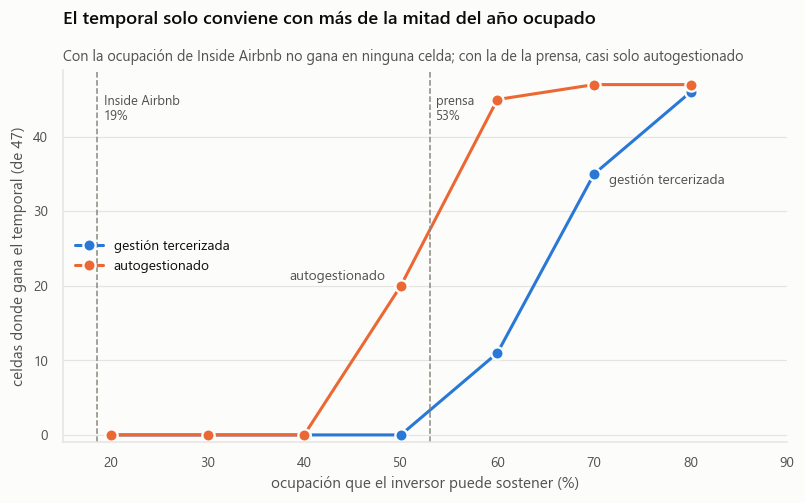

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
grilla = base[base["ocupacion_sostenible_pct"].isin(S.SENSIBILIDAD_OCUPACION)]
# Rotulo directo de cada curva sobre su tramo empinado, donde no se cruzan.
rotulos = {"tercerizada": (70, (10, -4), "left", "gestión tercerizada"),
           "autogestionado": (50, (-10, 6), "right", "autogestionado")}
for gestion, color in [("tercerizada", eda.SERIE_1), ("autogestionado", eda.SERIE_2)]:
    g = grilla[grilla["gestion"] == gestion].sort_values("ocupacion_sostenible_pct")
    ax.plot(g["ocupacion_sostenible_pct"], g["gana_temporal"], color=color, marker="o",
            markeredgecolor=eda.SUPERFICIE, markeredgewidth=1.5, label=rotulos[gestion][3])
    x_r, off, ha, texto = rotulos[gestion]
    ax.annotate(texto, (x_r, g.set_index("ocupacion_sostenible_pct").loc[x_r, "gana_temporal"]), xytext=off,
                textcoords="offset points", fontsize=9, color=eda.TINTA_2, ha=ha, va="center")
oc_airbnb = temporal["ocupacion_mediana_pct"].median()
for x_, texto in [(oc_airbnb, f"Inside Airbnb\n{oc_airbnb:.0f}%"), (S.OCUPACION_REF_PCT, f"prensa\n{S.OCUPACION_REF_PCT:.0f}%")]:
    ax.axvline(x_, color=eda.TINTA_3, linewidth=1, linestyle="--")
    ax.annotate(texto, (x_, len(temporal) * 0.97), xytext=(4, 0), textcoords="offset points", fontsize=8.5,
                color=eda.TINTA_2, va="top")
ax.set_xlim(15, 90)
ax.set_ylim(-1, len(temporal) + 2)
ax.set_xlabel("ocupación que el inversor puede sostener (%)")
ax.set_ylabel(f"celdas donde gana el temporal (de {len(temporal)})")
ax.legend(loc="center left")
eda.titulo(ax, "El temporal solo conviene con más de la mitad del año ocupado",
           "Con la ocupación de Inside Airbnb no gana en ninguna celda; con la de la prensa, casi solo autogestionado")
eda.guardar(fig, 15, "p3_ocupacion")
plt.show()

**Lectura. P3 se responde tradicional, con una condición.**

- **Con gestión tercerizada**, el temporal necesita una ocupación cercana al 65% para
  empatar. Con la ocupación que estima Inside Airbnb no gana en ninguna celda, y con el
  53% que informa la prensa gana en 2 de 47.
- **Autogestionado**, el umbral baja a alrededor de 52%, y con el 53% de la prensa gana en
  más de la mitad de las celdas.

El temporal conviene solo para un inversor que lo opere por su cuenta y que tenga
evidencia de poder sostener más de la mitad del año ocupado. Las dos ocupaciones de
referencia son estimaciones, no datos observados, y autogestionar es un trabajo, no un
ahorro (`supuestos.py`, sección 4c).

## 5. Sensibilidad: ¿cuánto depende la recomendación de los supuestos?

Un parámetro por vez, con los demás en el caso base, y dos escenarios extremos que mueven
todo a favor y todo en contra de comprar. Para cada escenario se compara el conjunto
recomendado con el del caso base mediante el índice de Jaccard: 1 significa las mismas
propiedades, 0, ninguna en común.

In [12]:
cols = ["parametro", "vacancia", "gastos_sin_abl", "abl", "entrada", "umbral", "margen", "n_p1", "n_p1_con_entrada",
        "jaccard_p1_vs_base", "n_frontera_p2", "jaccard_frontera_vs_base", "pares_distinguibles_pct"]
sens[cols]

,parametro,vacancia,gastos_sin_abl,abl,entrada,umbral,margen,n_p1,n_p1_con_entrada,jaccard_p1_vs_base,n_frontera_p2,jaccard_frontera_vs_base,pares_distinguibles_pct
0,base,5.88,10.24,segmentado,base,7.60,0.00,18,4,1.00,140,1.00,7.28
1,vacancia,4.00,10.24,segmentado,base,7.60,0.00,23,4,0.78,140,1.00,7.28
2,vacancia,6.00,10.24,segmentado,base,7.60,0.00,18,4,1.00,140,1.00,7.28
3,vacancia,8.00,10.24,segmentado,base,7.60,0.00,16,4,0.89,140,1.00,7.28
4,vacancia,10.00,10.24,segmentado,base,7.60,0.00,12,3,0.67,140,1.00,7.28
5,vacancia,12.00,10.24,segmentado,base,7.60,0.00,10,3,0.56,140,1.00,7.28
6,gastos sin ABL,5.88,8.24,segmentado,base,7.60,0.00,23,4,0.78,138,0.99,7.29
7,gastos sin ABL,5.88,10.24,segmentado,base,7.60,0.00,18,4,1.00,140,1.00,7.28
8,gastos sin ABL,5.88,12.24,segmentado,base,7.60,0.00,16,3,0.89,140,1.00,7.26
9,ABL,5.88,10.24,plano,base,7.60,0.00,20,4,0.90,92,0.66,8.14


In [13]:
q = p3[p3["ocupacion_sostenible_pct"] == S.OCUPACION_REF_PCT].pivot(index="vacancia_tradicional_pct",
                                                                     columns="gestion", values="gana_temporal")
print(f"P3: celdas donde gana el temporal con {S.OCUPACION_REF_PCT:.0f}% de ocupacion, segun la vacancia del tradicional")
q

P3: celdas donde gana el temporal con 53% de ocupacion, segun la vacancia del tradicional


gestion,autogestionado,tercerizada
vacancia_tradicional_pct,,
4.00,27,1
5.88,28,2
6.00,28,2
8.00,30,2
10.00,34,3
12.00,36,3


**Lectura.**

- **P1 es robusto en su conclusión, no en su lista.** En todos los escenarios pasa menos
  del 1,5% del universo, incluido el extremo favorable. Sin embargo, qué propiedades
  pasan cambia bastante: con un margen por liquidez de 1 punto quedan un tercio de las
  del caso base. Con costos de entrada, el resultado es casi nulo en todos los escenarios
  salvo en el que no tiene costos de entrada.
- **La frontera de P2 casi no se mueve.** La vacancia y los gastos sin ABL escalan todas
  las netas por igual y no cambian qué banda domina a cuál. Lo único que la mueve es la
  definición del ABL: con el plano, la frontera se achica a 92 propiedades, porque el
  plano les cobra de más a las unidades baratas, que son las que llegan a la frontera.
  En todos los escenarios, los pares distinguibles quedan entre 7% y 8%.
- **P3 no cambia de signo** con ninguna vacancia razonable del tradicional.
- **La banda de retorno importa más que los gastos.** Usar el piso (7,10%) en lugar del
  techo casi duplica las que pasan P1. Por eso el criterio declarado usa el techo: es la
  vara exigente, la que corresponde a una decisión que no se puede deshacer barato.

## Resumen: qué recomienda la función de decisión

| Decisión | Recomendación | Evaluación |
|---|---|---|
| **P1** — ¿comprar? | **No, para la propiedad típica.** Solo 18 de 4.484 propiedades superan el techo en el escenario pesimista, y 4 con costos de entrada | Las que pasan son baratas para su celda: verificar el aviso antes de cualquier decisión. Robusto en la conclusión en todos los escenarios, inestable en la lista |
| **P2** — ¿cuál? | **Una lista corta, no una propiedad.** 140 propiedades no dominadas, que no se distinguen entre sí | Solo el 7% de los pares se distingue con la banda. Desempate por ancho de banda (riesgo de estimación); la liquidez disponible no discrimina |
| **P3** — ¿tradicional o temporal? | **Tradicional**, salvo un inversor que autogestione y pueda sostener más de alrededor de 52% de ocupación | Con gestión tercerizada el equilibrio mediano es 65,5%; la ocupación observable no lo alcanza en ninguna celda |

**Lo que la función no hace.**
- No incluye apreciación ni costos de salida.
- No incluye riesgo legal, que es una limitación declarada.
- No incluye casas ni PH, que están fuera del soporte del modelo.
- La liquidez es la de toda la Ciudad por cantidad de ambientes, no la de cada propiedad.
- Todos los precios son de publicación, de una sola inmobiliaria.